In [14]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report, confusion_matrix, ConfusionMatrixDisplay



In [15]:
df = pd.read_csv('Student_Performance.csv')
print('Dataset shape:', df.shape)
print('\nFirst five rows:\n', df.head())
print('\nMissing values:\n', df.isnull().sum())



Dataset shape: (10000, 6)

First five rows:
    Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  

Missing values:
 Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours       

In [16]:
df['Extracurricular Activities'] = df['Extracurricular Activities'].map({'No': 0, 'Yes': 1})
df['Performance Category'] = pd.cut(df['Performance Index'], bins=[0, 40, 70, 100], labels=['Low', 'Medium', 'High'], include_lowest=True)
print('\nPerformance categories:\n', df['Performance Category'].value_counts())




Performance categories:
 Performance Category
Medium    4933
Low       2562
High      2505
Name: count, dtype: int64


In [17]:
X = df.drop(columns=['Performance Index', 'Performance Category'])
y = df['Performance Category']



In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('\nTraining samples:', len(X_train))
print('Testing samples:', len(X_test))




Training samples: 8000
Testing samples: 2000


In [19]:
k_values = [1, 3, 5, 7, 9, 11]
cv_accuracies = []
for k in k_values:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    cv_accuracies.append(scores.mean())
    print(f'K={k}: Average CV accuracy={scores.mean():.4f}')

best_k = k_values[cv_accuracies.index(max(cv_accuracies))]
print('\nBest K:', best_k)



K=1: Average CV accuracy=0.8858
K=3: Average CV accuracy=0.9029
K=5: Average CV accuracy=0.9075
K=7: Average CV accuracy=0.9102
K=9: Average CV accuracy=0.9141
K=11: Average CV accuracy=0.9150

Best K: 11


In [20]:
best_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)



In [21]:
print('\nTest Accuracy:', accuracy_score(y_test, y_pred))
print('Weighted Precision:', precision_score(y_test, y_pred, average='weighted', zero_division=0))
print('Weighted Recall:', recall_score(y_test, y_pred, average='weighted', zero_division=0))
print('\nClassification Report:\n', classification_report(y_test, y_pred, zero_division=0))
print('\nConfusion Matrix:\n', confusion_matrix(y_test, y_pred, labels=['Low', 'Medium', 'High']))




Test Accuracy: 0.92
Weighted Precision: 0.9203135257666759
Weighted Recall: 0.92

Classification Report:
               precision    recall  f1-score   support

        High       0.93      0.91      0.92       501
         Low       0.93      0.91      0.92       512
      Medium       0.91      0.93      0.92       987

    accuracy                           0.92      2000
   macro avg       0.92      0.92      0.92      2000
weighted avg       0.92      0.92      0.92      2000


Confusion Matrix:
 [[465  47   0]
 [ 35 920  32]
 [  0  46 455]]


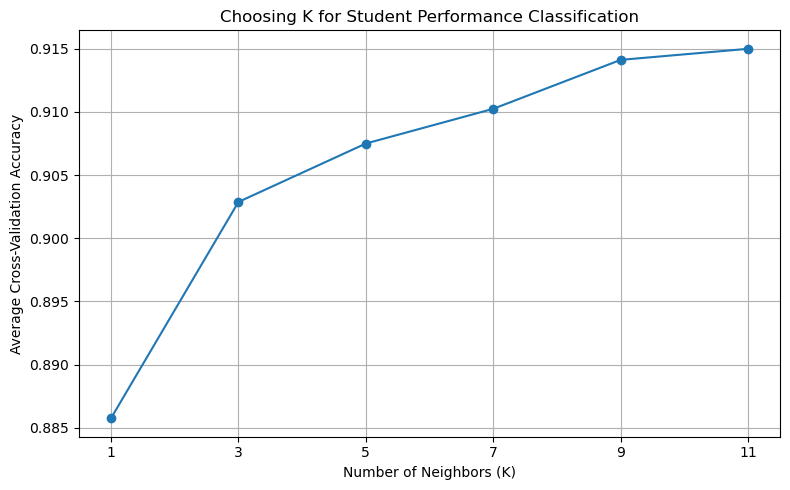

In [22]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, cv_accuracies, marker='o')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Average Cross-Validation Accuracy')
plt.title('Choosing K for Student Performance Classification')
plt.xticks(k_values)
plt.grid(True)
plt.tight_layout()
plt.show()




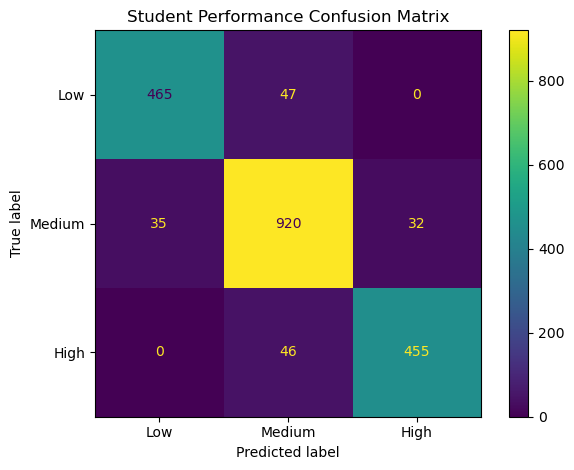


Predicted category for new student: High


In [23]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=['Low', 'Medium', 'High'])
plt.title('Student Performance Confusion Matrix')
plt.tight_layout()
plt.show()

new_student = pd.DataFrame([[7, 85, 1, 7, 5]], columns=X.columns)
print('\nPredicted category for new student:', best_model.predict(new_student)[0])